# 12 — Single and multiple shooting

**Objectives.** Derive both transcriptions and expose the sparse continuity constraints. For $x_{k+1}=F(x_k,u_k)$, single shooting eliminates every state by repeated substitution. Multiple shooting keeps $x_k$ as decisions and imposes $x_{k+1}-F(x_k,u_k)=0$. The latter is larger but sparse and permits state initialization and path constraints directly.


In [1]:
# Make repository-local helpers importable without installing a package.
import sys
from pathlib import Path

repository_root = next(
    candidate
    for candidate in (Path.cwd(), *Path.cwd().parents)
    if (candidate / "casadi_tutorial").is_dir()
)
if str(repository_root) not in sys.path:
    sys.path.insert(0, str(repository_root))

# Autoreload picks up edits to tutorial models before each notebook cell runs.
ipython = get_ipython()
if ipython is not None:
    ipython.run_line_magic("load_ext", "autoreload")
    ipython.run_line_magic("autoreload", "2")

### Transcribe a double-integrator control problem by multiple shooting

The cell defines continuous dynamics, constructs one RK4 transition
`Function`, and introduces an Opti state at every mesh point. Equality
constraints connect neighboring states through the transition function.
This is multiple shooting: states are decision variables rather than
being hidden inside one long simulation.

The plant is

$$
\dot q=v,\qquad \dot v=u,
$$

and each shooting constraint is

$$
x_{k+1}=F_{\mathrm{RK4}}(x_k,u_k;h).
$$

The finite-horizon problem is

$$
\min_{x,u}\;h\sum_{k=0}^{N-1}u_k^2
$$

subject to $x_0=[0,0]^\mathsf{T}$,
$x_N=[1,0]^\mathsf{T}$, the shooting equations, and
$-2\le u_k\le2$. A linear position profile provides a useful initial
guess but does not constrain the final solution.

The solution plot uses $x$ for the two state components and $u$ for the manipulated acceleration, with the input drawn as a held signal over each shooting interval.



******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************

objective: 1.5037593984962403 iterations: 5


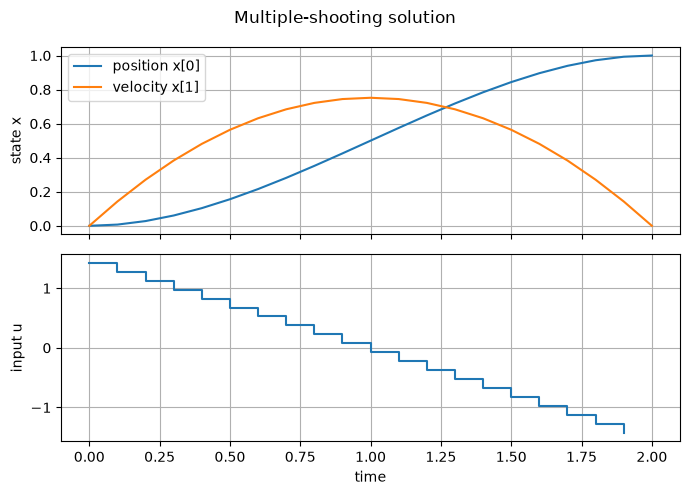

In [2]:
import casadi as ca
import matplotlib.pyplot as plt
import numpy as np

from casadi_tutorial.integration import rk4_step


def double_integrator_rhs(x, u):
    """Return the state derivative for manipulated acceleration u."""
    return ca.vertcat(x[1], u[0])


number_of_intervals = 20
horizon = 2.0
step_size = horizon / number_of_intervals

x_symbol = ca.MX.sym("x", 2)
u_symbol = ca.MX.sym("u", 1)
discrete_dynamics = ca.Function(
    "discrete_dynamics",
    [x_symbol, u_symbol],
    [
        rk4_step(
            double_integrator_rhs,
            x_symbol,
            u_symbol,
            step_size,
        )
    ],
    ["x", "u"],
    ["x_next"],
)

optimization = ca.Opti()
x = optimization.variable(2, number_of_intervals + 1)
u = optimization.variable(1, number_of_intervals)
optimization.subject_to(x[:, 0] == [0, 0])
for index in range(number_of_intervals):
    optimization.subject_to(x[:, index + 1] == discrete_dynamics(x[:, index], u[:, index]))

optimization.subject_to(x[:, -1] == [1, 0])
optimization.subject_to(optimization.bounded(-2, u, 2))
optimization.minimize(step_size * ca.sumsqr(u))
optimization.set_initial(
    x[0, :],
    np.linspace(0, 1, number_of_intervals + 1),
)
optimization.solver(
    "ipopt",
    {"print_time": False},
    {"print_level": 0},
)

solution = optimization.solve()
x_solution = solution.value(x)
u_solution = np.atleast_2d(solution.value(u))
print(
    "objective:",
    solution.value(optimization.f),
    "iterations:",
    solution.stats()["iter_count"],
)
np.testing.assert_allclose(x_solution[:, -1], [1, 0], atol=1e-7)

x_time = np.linspace(0, horizon, number_of_intervals + 1)
u_time = x_time[:-1]
figure, axes = plt.subplots(2, 1, sharex=True, figsize=(7, 5))
axes[0].plot(x_time, x_solution[0], label="position x[0]")
axes[0].plot(x_time, x_solution[1], label="velocity x[1]")
axes[0].set_ylabel("state x")
axes[0].legend()
axes[0].grid(True)
axes[1].step(u_time, u_solution.ravel(), where="post")
axes[1].set(xlabel="time", ylabel="input u")
axes[1].grid(True)
figure.suptitle("Multiple-shooting solution")
figure.tight_layout()
plt.show()

### Inspect the sparse constraint Jacobian of the transcription

`ca.vec` stacks each matrix column into a vector, matching CasADi's
column-major ordering. `ca.vertcat` joins the state and control blocks into
one decision vector, and `ca.jacobian` differentiates the complete Opti
constraint vector with respect to it.

If

$$
w=\operatorname{vertcat}(\operatorname{vec}(x),
\operatorname{vec}(u)),
$$

the matrix being inspected is

$$
J_g(w)=\frac{\partial g(w)}{\partial w}.
$$

Each dynamic defect depends only on $x_k$, $u_k$, and $x_{k+1}$, so
the Jacobian is block-banded rather than dense. The reported structural
nonzero count quantifies that exploitable sparsity.


In [3]:
# vec stacks x and u by columns in the NLP decision-vector ordering.
decision_vector = ca.vertcat(ca.vec(x), ca.vec(u))
constraint_jacobian = ca.jacobian(optimization.g, decision_vector)
print(
    "constraint Jacobian shape:",
    constraint_jacobian.shape,
    "structural nonzeros:",
    constraint_jacobian.nnz(),
)

constraint Jacobian shape: (64, 62) structural nonzeros: 164


Single shooting is easy and has few variables but can be ill-conditioned for unstable/long horizons. Multiple shooting has a block-banded Jacobian and usually offers better initialization. Mesh refinement compares solutions at increasing $N$; it is not enough that one mesh converges.

**Recap:** transcription determines NLP structure before the solver sees the problem.
